In [1]:
import sys, os
sys.path.append(os.path.abspath(".."))

In [2]:
import torch

print("Torch:", torch.__version__)
print("Torch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())

Torch: 2.6.0+cu124
Torch CUDA: 12.4
CUDA available: True


In [3]:
import torch

from utils.seed import set_seed

SEED = 42
set_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("=" * 50)
print(f"Seed   : {SEED}")
print(f"Device : {DEVICE}")

if torch.cuda.is_available():
    print(f"GPU    : {torch.cuda.get_device_name(0)}")

print("=" * 50)

Seed set to: 42
Seed   : 42
Device : cuda
GPU    : Tesla T4


In [4]:
import pandas as pd

from benchmarks.benchmark_factory import build_benchmark
from models.model_factory import build_model
from evaluation.evaluator_factory import build_evaluator
from strategies.strategy_factory import build_strategy
from experiments.runner import run_continual_experiment, run_joint_experiment
from evaluation.plots import *

In [5]:
benchmark_name = "split_mnist"
model_name = "avalanche_simplemlp"
n_experiences = 5
num_classes = 10

seed = 124

EXPERIMENTS = [
    {
        "name": "joint",
        "strategy_name": "joint",
        "plugin_names": [],
        "lr": 0.01,
        "train_epochs": 5,
    },
    {
        "name": "naive",
        "strategy_name": "naive",
        "plugin_names": [],
        "lr": 0.01,
        "train_epochs": 1,
    },
    {
        "name": "ewc",
        "strategy_name": "naive",
        "plugin_names": ["ewc"],
        "ewc_lambda": 0.4,
        "lr": 0.01,
        "train_epochs": 1,
    },
    {
        "name": "replay",
        "strategy_name": "naive",
        "plugin_names": ["replay"],
        "mem_size": 500,
        "lr": 0.01,
        "train_epochs": 1,
    },
    {
        "name": "ewc_replay",
        "strategy_name": "naive",
        "plugin_names": ["ewc", "replay"],
        "ewc_lambda": 0.4,
        "mem_size": 500,
        "lr": 0.01,
        "train_epochs": 1,
    },
]

all_results = {}

for config in EXPERIMENTS:
    approach_name = config["name"]
    strategy_name = config["strategy_name"]

    output_dir = f"../outputs/{benchmark_name}/{approach_name}/{model_name}/"

    print("\n" + "=" * 80)
    print(f"Running: {approach_name}")
    print("=" * 80)

    benchmark = build_benchmark(
        benchmark_name=benchmark_name,
        n_experiences=n_experiences,
        seed=seed,
    )

    model = build_model(
        model_name=model_name,
        num_classes=num_classes,
    ).to(DEVICE)

    evaluator = build_evaluator(
        log_dir=output_dir + "logs",
        use_interactive=False,
        use_text=False,
        use_tensorboard=True,
    )

    strategy_kwargs = {
        k: v for k, v in config.items()
        if k not in [
            "name",
            "strategy_name",
            "plugin_names",
            "lr",
            "train_epochs",
        ]
    }

    strategy = build_strategy(
        strategy_name=strategy_name,
        model=model,
        evaluator=evaluator,
        optimizer_name="sgd",
        lr=config["lr"],
        momentum=0.9,
        train_mb_size=64,
        eval_mb_size=128,
        train_epochs=config["train_epochs"],
        plugin_names=config.get("plugin_names"),
        device=DEVICE,
        **strategy_kwargs,
    )

    if strategy_name == "joint":
        result = run_joint_experiment(
            strategy=strategy,
            benchmark=benchmark,
            output_dir=output_dir,
            save_outputs=False,
        )
    else:
        result = run_continual_experiment(
            strategy=strategy,
            benchmark=benchmark,
            output_dir=output_dir,
            save_outputs=False,
        )

    all_results[approach_name] = result


Running: joint
Training JointTraining on full train stream
Evaluating JointTraining on full test stream

Running: naive
Training experience 1/5
Evaluating on full test stream
Training experience 2/5
Evaluating on full test stream
Training experience 3/5
Evaluating on full test stream
Training experience 4/5
Evaluating on full test stream
Training experience 5/5
Evaluating on full test stream

Running: ewc
Training experience 1/5
Evaluating on full test stream
Training experience 2/5
Evaluating on full test stream
Training experience 3/5
Evaluating on full test stream
Training experience 4/5
Evaluating on full test stream
Training experience 5/5
Evaluating on full test stream

Running: replay
Training experience 1/5


/opt/conda/envs/hds-cl/lib/python3.10/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream
Training experience 2/5


/opt/conda/envs/hds-cl/lib/python3.10/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream
Training experience 3/5


...

Evaluating on full test stream
Training experience 4/5


/opt/conda/envs/hds-cl/lib/python3.10/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream
Training experience 5/5


/opt/conda/envs/hds-cl/lib/python3.10/site-packages/avalanche/training/plugins/replay.py:123: DeprecationWarning: Call to deprecated function update (removal in version 0.7: switch to pre_adapt and post_adapt)
  self.storage_policy.update(strategy, **kwargs)


Evaluating on full test stream


In [6]:
rows = []

for name, result in all_results.items():
    row = {"Strategy": name}
    row.update(result["metrics"])
    rows.append(row)

df = pd.DataFrame(rows)
df = df.round(4)
df = df.sort_values(by="A Metric", ascending=False)
display(df)

,Strategy,A Metric,ACC Metric,Model Size,BWT (Backward Transfer),BWT+ (Positive Backward Transfer),FWT (Forward Transfer),Forgetting,REM (Remembering),MS (Memory Score),SSS (Sample Storage Score),CE (Compute Efficiency),Total Train Time,Average Train Time,Estimated Baseline Ops,Estimated Total Ops
0,joint,0.9803,NaN,407050,NaN,NaN,NaN,NaN,NaN,1.0,1.0000,1.00,52.4333,52.4333,2.442300e+10,2.442300e+10
4,ewc_replay,0.8976,0.9336,407050,-0.1037,0.0,0.0,0.1037,0.8963,1.0,0.9917,0.96,27.4813,5.4963,2.442300e+10,2.544062e+10
3,replay,0.8956,0.9315,407050,-0.1055,0.0,0.0,0.1055,0.8945,1.0,0.9917,0.96,17.3172,3.4634,2.442300e+10,2.544062e+10
1,naive,0.1975,0.3308,407050,-0.9937,0.0,0.0,0.9937,0.0063,1.0,1.0000,1.00,10.8792,2.1758,2.442300e+10,2.442300e+10
2,ewc,0.1961,0.3304,407050,-0.9939,0.0,0.0,0.9939,0.0061,1.0,1.0000,1.00,21.1341,4.2268,2.442300e+10,2.442300e+10


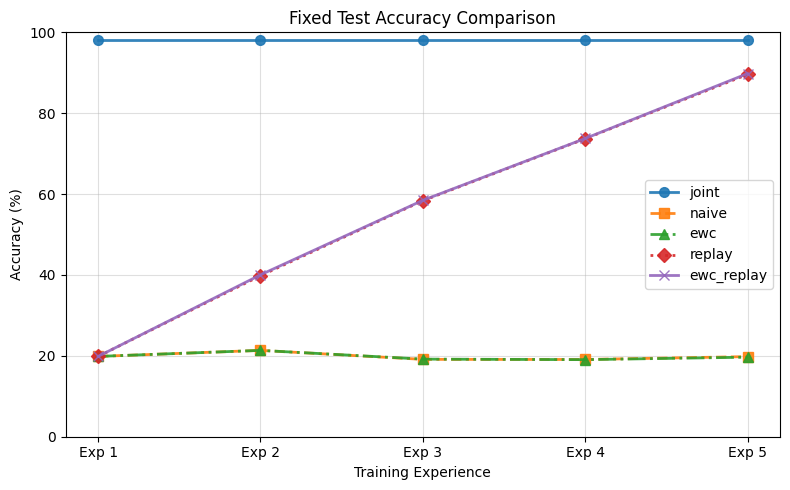

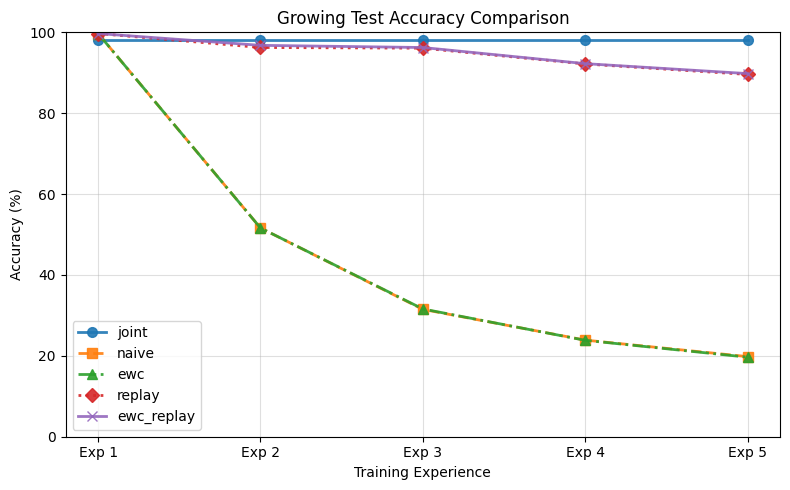

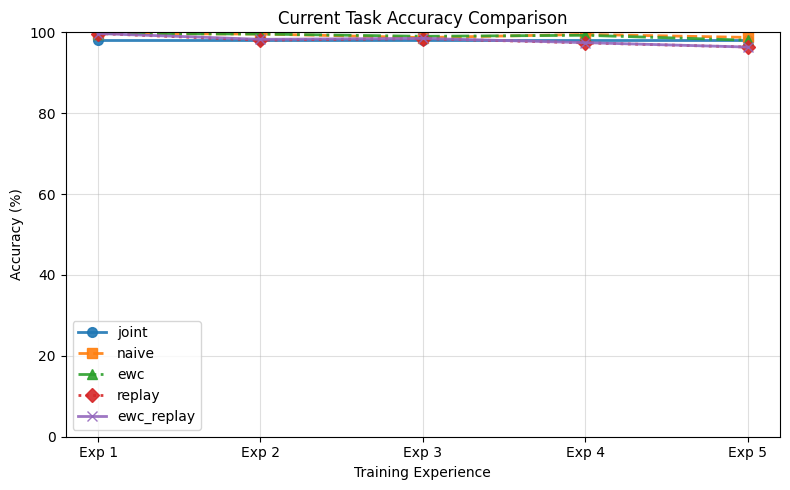

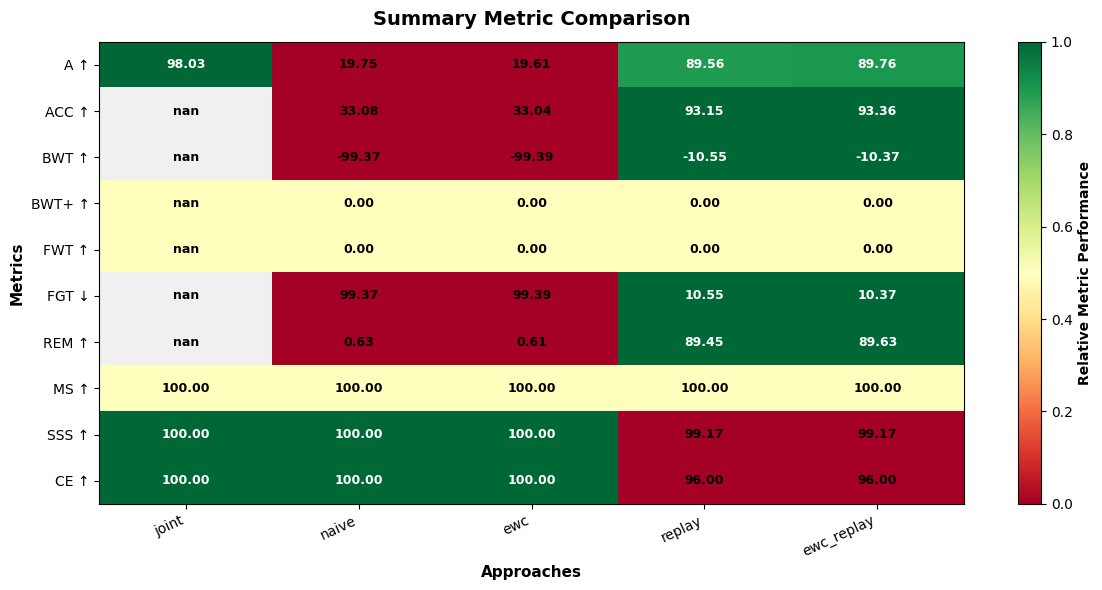

In [7]:
plot_fixed_comparison(all_results)
plot_growing_comparison(all_results)
plot_task_comparison(all_results)
plot_metric_comparison(all_results)

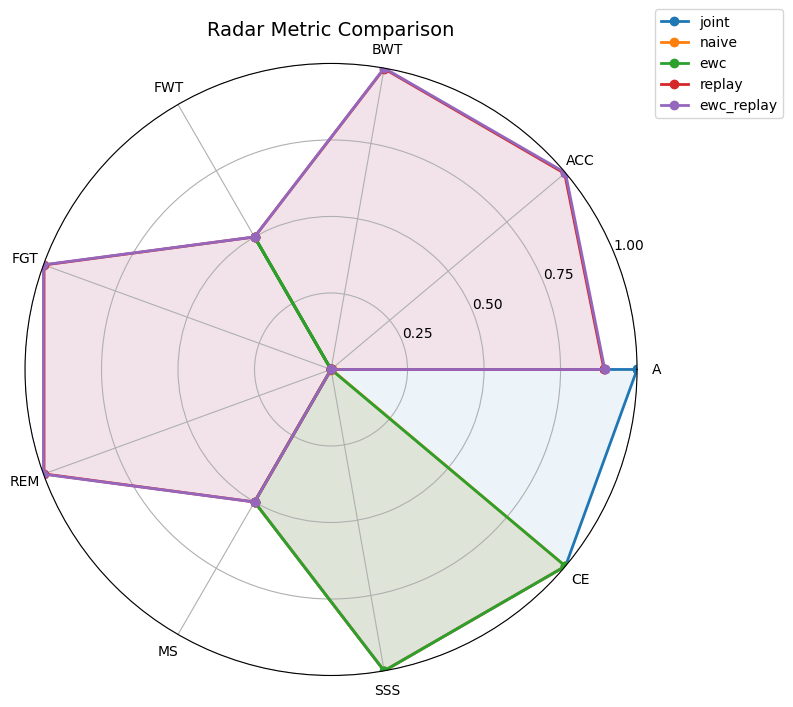

In [8]:
plot_radar_metrics(
    all_results,
    metric_names={
        "A Metric": "A",
        "ACC Metric": "ACC",
        "BWT (Backward Transfer)": "BWT",
        "FWT (Forward Transfer)": "FWT",
        "Forgetting": "FGT",
        "REM (Remembering)": "REM",
        "MS (Memory Score)": "MS",
        "SSS (Sample Storage Score)": "SSS",
        "CE (Compute Efficiency)": "CE",
    },
)